# Lab: Longest Common Subsequence
## Recursion, Dynamic Programming, and Timing Comparison

### Objectives
- understand the LCS recurrence;
- implement recursive and dynamic programming solutions;
- compare their running times; and
- use LCS to study palindromes.

## 1. Mathematical idea

For sequences `X` and `Y`, let `L(i, j)` be the LCS length of `X[:i]` and `Y[:j]`.

```text
L(i, j) = 0                                  if i = 0 or j = 0
L(i, j) = 1 + L(i-1, j-1)                  if X[i-1] = Y[j-1]
L(i, j) = max(L(i-1, j), L(i, j-1))        otherwise
```

- If either prefix is empty, the LCS length is `0`.
- If the last elements match, include that element.
- Otherwise, ignore one of the two last elements and keep the better result.

## 2. Recursive method

In [6]:
def lcs_recursive(x, y, i=None, j=None):
    """Return the LCS length using direct recursion."""
    if i is None:
        i = len(x)
    if j is None:
        j = len(y)

    if i == 0 or j == 0:
        return 0

    if x[i - 1] == y[j - 1]:
        return 1 + lcs_recursive(x, y, i - 1, j - 1)

    remove_from_x = lcs_recursive(x, y, i - 1, j)
    remove_from_y = lcs_recursive(x, y, i, j - 1)
    return max(remove_from_x, remove_from_y)


x = "ABCBDAB"
y = "BDCABA"
print("Recursive LCS length:", lcs_recursive(x, y))

Recursive LCS length: 4


The recursive method follows the recurrence directly, but repeatedly solves the same subproblems. Its running time can therefore grow exponentially.

## 3. Dynamic programming method

In [11]:
def lcs_dp(x, y):
    """Return the LCS length and its dynamic programming table."""
    m, n = len(x), len(y)
    table = [[0] * (n + 1) for _ in range(m + 1)]

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if x[i - 1] == y[j - 1]:
                table[i][j] = 1 + table[i - 1][j - 1]
            else:
                table[i][j] = max(table[i - 1][j], table[i][j - 1])

    return table[m][n], table

length, table = lcs_dp(x, y)
print("DP LCS length:", length)

DP LCS length: 4


The table has `(m + 1)(n + 1)` entries. Each entry takes constant work.

- Time complexity: `O(mn)`
- Space complexity: `O(mn)`

## 4. Finding one LCS

In [11]:
def one_lcs(x, y):
    """Return one longest common subsequence."""
    _, table = lcs_dp(x, y)
    i, j = len(x), len(y)
    answer = []

    while i > 0 and j > 0:
        if x[i - 1] == y[j - 1]:
            answer.append(x[i - 1])
            i -= 1
            j -= 1
        elif table[i - 1][j] >= table[i][j - 1]:
            i -= 1
        else:
            j -= 1

    return "".join(reversed(answer))


print("One LCS:", one_lcs(x, y))

One LCS: BCBA


## 5. Timing comparison

The same generated pair is used for both methods at each input length. Several trials are averaged because a single timing can fluctuate.

Only small lengths are used because direct recursion becomes slow rapidly.

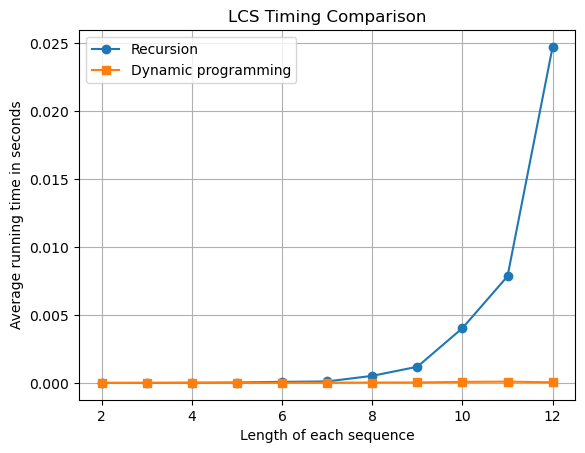

In [12]:
import random
import time
import matplotlib.pyplot as plt

random.seed(10)
lengths = list(range(2, 13))
recursive_times = []
dp_times = []
trials = 5

for n in lengths:
    recursive_total = 0
    dp_total = 0

    for _ in range(trials):
        x = "".join(random.choice("ABCD") for _ in range(n))
        y = "".join(random.choice("ABCD") for _ in range(n))

        start = time.perf_counter()
        recursive_answer = lcs_recursive(x, y)
        recursive_total += time.perf_counter() - start

        start = time.perf_counter()
        dp_answer, _ = lcs_dp(x, y)
        dp_total += time.perf_counter() - start

        assert recursive_answer == dp_answer

    recursive_times.append(recursive_total / trials)
    dp_times.append(dp_total / trials)

plt.plot(lengths, recursive_times, marker="o", label="Recursion")
plt.plot(lengths, dp_times, marker="s", label="Dynamic programming")
plt.xlabel("Length of each sequence")
plt.ylabel("Average running time in seconds")
plt.title("LCS Timing Comparison")
plt.legend()
plt.grid(True)
plt.show()

### Interpretation

The exact times depend on the computer and generated inputs. The important observation is the growth pattern: recursion repeats subproblems, whereas dynamic programming computes each table entry once.

## Exercise 1: Complete the recurrence

Complete the missing expressions and test the function with `"STONE"` and `"LONGEST"`.

In [2]:
def exercise_lcs(x, y):
    table = [[0] * (len(y) + 1) for _ in range(len(x) + 1)]

    for i in range(1, len(x) + 1):
        for j in range(1, len(y) + 1):
            if x[i - 1] == y[j - 1]:
                table[i][j] = 1 + table[i-1][j-1]
            else:
                table[i][j] = max(table[i-1][j], table[i][j-1])

    return table[len(x)][len(y)]

exercise_lcs("STONE","LONGEST")

3

## 6. Longest Palindromic Subsequence (LPS)

A **palindromic subsequence** reads the same from left to right and right to left. The **LPS** is the longest such subsequence.

Example: in `"CHARACTER"`, `"CARAC"` is a palindromic subsequence of length 5.

### LPS using LCS

If `s` is a string, then

```text
LPS length of s = LCS length of s and reverse(s)
```

Thus, we can reuse the LCS program:

In [9]:
def lps_using_lcs(s):
    reversed_s = s[::-1]
    length, _ = lcs_dp(s, reversed_s)
    return length


s = "CHARACTER"
print("LPS length using LCS:", lps_using_lcs(s))

LPS length using LCS: 5


### Direct interval dynamic programming

LPS can also be solved directly. Let `P(i, j)` be the LPS length in `s[i:j+1]`.

```text
P(i, i) = 1
P(i, j) = 2 + P(i+1, j-1)                 if s[i] = s[j]
P(i, j) = max(P(i+1, j), P(i, j-1))       otherwise
```

The table is filled from shorter substrings to longer substrings.

In [4]:
def lps_direct(s):
    """Return the LPS length using interval dynamic programming."""
    n = len(s)
    if n == 0:
        return 0

    table = [[0] * n for _ in range(n)]

    for i in range(n):
        table[i][i] = 1

    for length in range(2, n + 1):
        for i in range(n - length + 1):
            j = i + length - 1

            if s[i] == s[j]:
                middle = table[i + 1][j - 1] if length > 2 else 0
                table[i][j] = 2 + middle
            else:
                table[i][j] = max(table[i + 1][j], table[i][j - 1])

    return table[0][n - 1]


print("LPS length using direct DP:", lps_direct("CHARACTER"))

LPS length using direct DP: 5


### Is the LCS method the most efficient method for LPS?

Not always.

- LCS with the reversed string is simple because it reuses the LCS algorithm.
- Full-table LCS and direct interval DP both take `O(n²)` time and `O(n²)` space.
- If only the LPS length is needed, either formulation can be space-optimized to `O(n)` space while retaining `O(n²)` time.
- Direct interval DP is often the clearer formulation because it works directly with the palindrome structure and does not create a reversed string.

## Exercise 2: LPS problem

For

```text
s = "BBABCBCAB"
```

1. Find the LPS length using `lps_using_lcs`.
2. Verify the same length using `lps_direct`.
3. Find one longest palindromic subsequence.
4. Find the minimum number of deletions required to make the string a palindrome.

Use

```text
minimum deletions = len(s) - LPS length
```

In [10]:
s = "BBABCBCAB"

# 1. LPS length using LCS
lps_lcs_len = lps_using_lcs(s)
print(f"LPS length using LCS: {lps_lcs_len}")

# 2. Verify using direct DP
lps_dir_len = lps_direct(s)
print(f"LPS length using direct DP: {lps_dir_len}")

# 3. Minimum deletions required
min_deletions = len(s) - lps_dir_len
print(f"Minimum deletions required: {min_deletions}")

LPS length using LCS: 7
LPS length using direct DP: 7
Minimum deletions required: 2


## Summary

Both methods use the same recurrence. Recursion is mathematically direct but repeats work. Dynamic programming stores smaller answers and reduces the running time to `O(mn)`.